# CNN Animals10 데이터셋
- 웹에서 수집된 총 10가지 서로 다른 동물 카테고리의 이미지들로 구성되어 있습니다.
주로 이미지 분류 모델을 처음부터 학습시키거나 전이학습(Transfer Learning)을 실습하는 용도로 활용됩니다

[Animals10 데이터셋](https://www.kaggle.com/datasets/alessiocorrado99/animals10)

In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
sklearn.set_config(display="text")

In [2]:
# .env 파일에 있는 환경변수를 현재 Python 실행 환경으로 불러옴 
load_dotenv()

# 토큰 존재 여부를 확인 (텍스트의 앞 네글자만 출력)
print(os.environ["KAGGLE_API_TOKEN"][:4])

KGAT


In [3]:
# Kaggle API 객체를 만들고, 환경변수에 저장된 토큰으로 인증
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()


output_dir = "/Users/kdt_0900_lyn/ml/resoce/dataset"
os.makedirs(output_dir, exist_ok=True)
api.dataset_download_files("alessiocorrado99/animals10", path=output_dir, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/alessiocorrado99/animals10
다운로드 완료


## iamageFolder
- 라벨링 폴더를 가져와서 각 폴더의 레이블로 묶어주는 모듈
- 

In [4]:
base_path = output_dir
# 폴더 경로 만듬
folder_name = r"raw-img"
file_path = os.path.join(base_path, folder_name)

In [5]:
file_path

'/Users/kdt_0900_lyn/ml/resoce/dataset/raw-img'

In [6]:
base_dataset = ImageFolder(root=file_path , transform= None)   # transform= None : 학습용, 테스트용 변환을 다르게 적용 
print(len(base_dataset))

26179


In [7]:
total_size = len(base_dataset)
train_size = int(total_size * 0.8)
test_size = total_size - train_size

## random_split()
길이 만큼 데이어를 랜덤하게 나눈 모듈 

In [8]:
print(train_size, test_size)

20943 5236


In [9]:
train_subset, test_subset = random_split(base_dataset, [train_size, test_size])

## transform 정의 

In [46]:
train_transforms = transforms.Compose([
    
    # 모든 사진의 크기fmf 64x64로 통일 
    transforms.Resize((64, 64)),
    # 컬러 RGB이미지를 채널1개의 흑백이미지로 변환 
    transforms.Grayscale(1),
    # 
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5)
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5)
])

In [11]:
# class DatasetWrapper(Dataset):
#     def __init__(self, dataset, tr):

In [12]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, tranform=None):
        self.dataset =dataset
        self.tranform = tranform
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.tranform:
            x = self.tranform(x)
        return x, y

In [13]:
train_dataset = DatasetWrapper(train_subset, tranform=train_transforms)
test_dataset = DatasetWrapper(test_subset, tranform=test_transform)

In [14]:
print(len(train_dataset), len(test_dataset))

20943 5236


In [15]:
class_dict = dict(enumerate(base_dataset.classes))
print(class_dict)

{0: 'cane', 1: 'cavallo', 2: 'elefante', 3: 'farfalla', 4: 'gallina', 5: 'gatto', 6: 'mucca', 7: 'pecora', 8: 'ragno', 9: 'scoiattolo'}


## 데이터 로더 (DataLoder)

In [16]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [17]:
img, labels = next(iter(test_dataloader))

In [18]:
print(img.size())

torch.Size([64, 1, 64, 64])


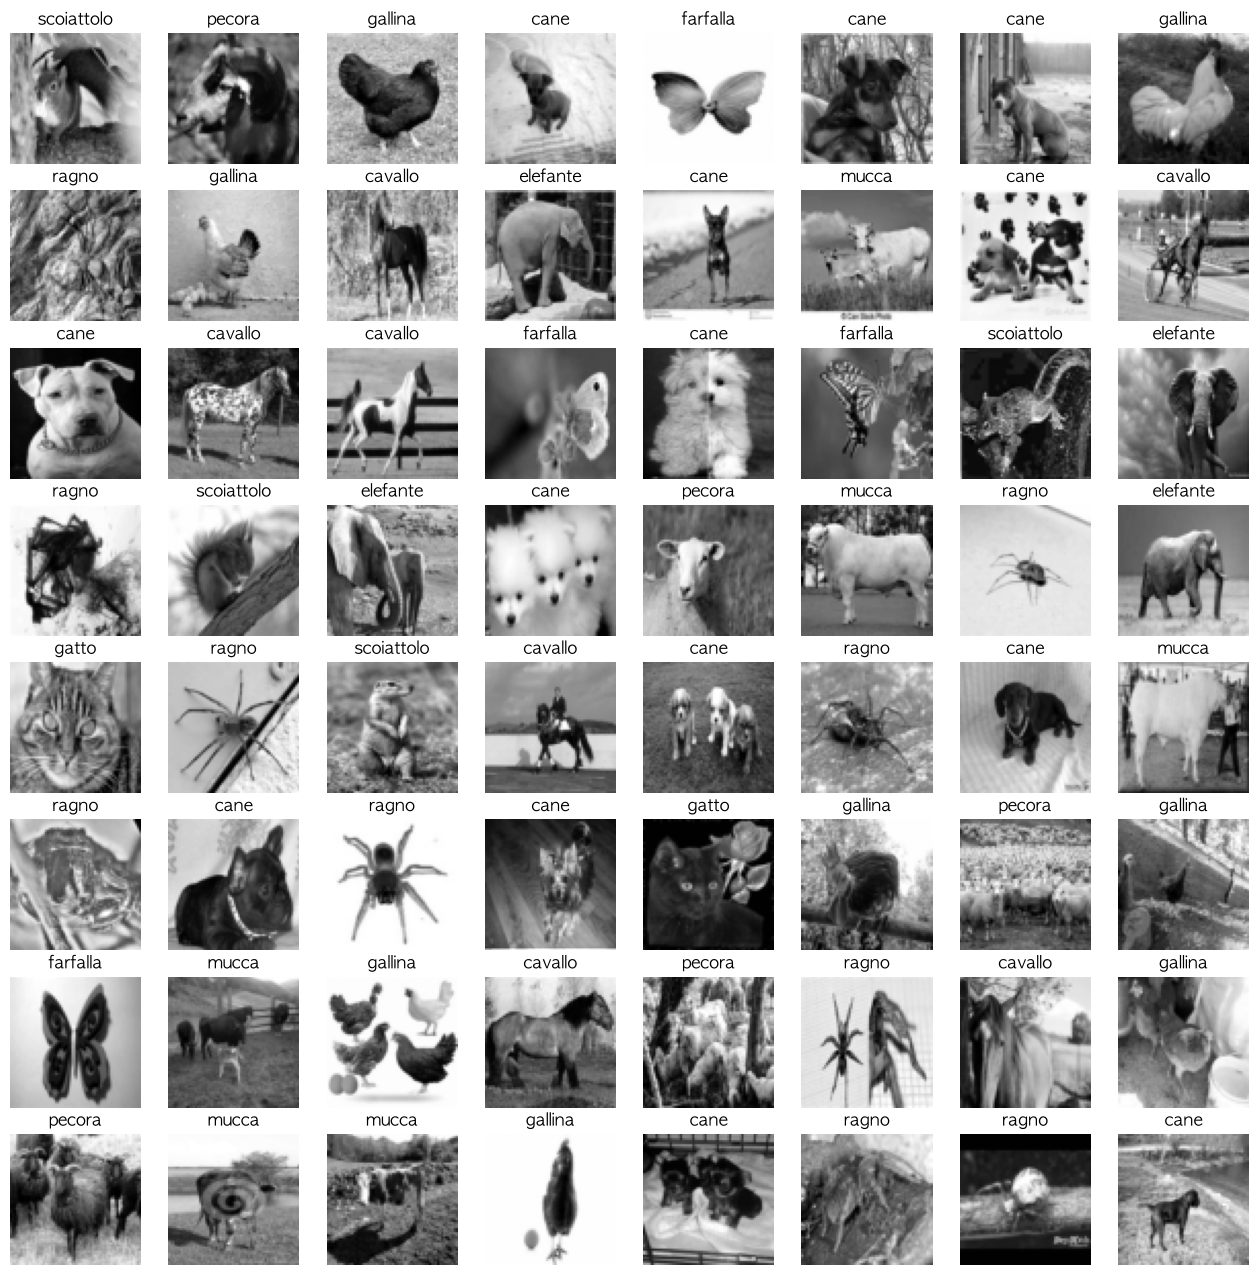

In [19]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))  
# 8행x8열 , 총 64개 그래프 칸   ,   전체 그림 크기

for ax, image_tensor, label in zip(axes.flatten(), img, labels):
    # 2차원 그래프칸을 일렬로 핌                       , 이미지 텐서 , 정답 레이블 을 하나씩 묶어서 반복
    ax.imshow(image_tensor.squeeze(0), cmap="gray")
    # 이미지텐서의 채널 차원 크기가 1일 경우 squeeze(0)으로 제거   \cmap="gray": 흑백
    ax.set_title(class_dict[label.item()])
    # 눈금 숨기고, 64장 미리 그래프를 출력  
    ax.axis("off")
plt.show()

In [20]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


## CNN 모델 준비 


In [21]:
# [CNN 모델]
class ConvNenuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25),
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 10)

    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        return self.linear(x)

In [22]:
model = ConvNenuralNetwork().to(device)

In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)    
                # lr=0.001 : (값을 작게하는 이유 :) 값을 작게 해서 가중치를 줄여 가중치 폭주를 막기위함

In [24]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        # 초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss: {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [25]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size

    return running_loss / total, running_corrects / total

In [26]:
epochs = 30

for i in range(epochs):
    # 학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # 평가
    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc * 100:.2f}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}")

[Train] batch 20/328 | Loss: 2.1670 | Accuracy: 0.28
[Train] batch 40/328 | Loss: 2.0600 | Accuracy: 0.34
[Train] batch 60/328 | Loss: 2.0898 | Accuracy: 0.27
[Train] batch 80/328 | Loss: 2.1800 | Accuracy: 0.20
[Train] batch 100/328 | Loss: 2.1743 | Accuracy: 0.22
[Train] batch 120/328 | Loss: 2.0422 | Accuracy: 0.31
[Train] batch 140/328 | Loss: 2.1071 | Accuracy: 0.23
[Train] batch 160/328 | Loss: 1.8768 | Accuracy: 0.39
[Train] batch 180/328 | Loss: 1.7834 | Accuracy: 0.41
[Train] batch 200/328 | Loss: 1.9852 | Accuracy: 0.33
[Train] batch 220/328 | Loss: 1.9982 | Accuracy: 0.27
[Train] batch 240/328 | Loss: 1.7668 | Accuracy: 0.44
[Train] batch 260/328 | Loss: 2.0015 | Accuracy: 0.25
[Train] batch 280/328 | Loss: 1.6995 | Accuracy: 0.44
[Train] batch 300/328 | Loss: 1.7240 | Accuracy: 0.48
[Train] batch 320/328 | Loss: 1.8522 | Accuracy: 0.30
Epoch: 0/30
[Train] Loss: 1.9921 | Accuracy: 30.54
[Test] Loss: 1.8094 | Accuracy: 39.09
[Train] batch 20/328 | Loss: 1.6489 | Accuracy: 0.5

In [ ]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")
    # ax.imshow(img.permute(1, 2, 0), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.show()

In [38]:
img_path =r"/Users/iyena/Downloads/KakaoTalk_Photo_2026-10-12-10-15-55.jpeg"
img_path

'/Users/iyena/Downloads/KakaoTalk_Photo_2026-10-12-10-15-55.jpeg'

In [39]:
img = Image

In [40]:
from PIL import Imege

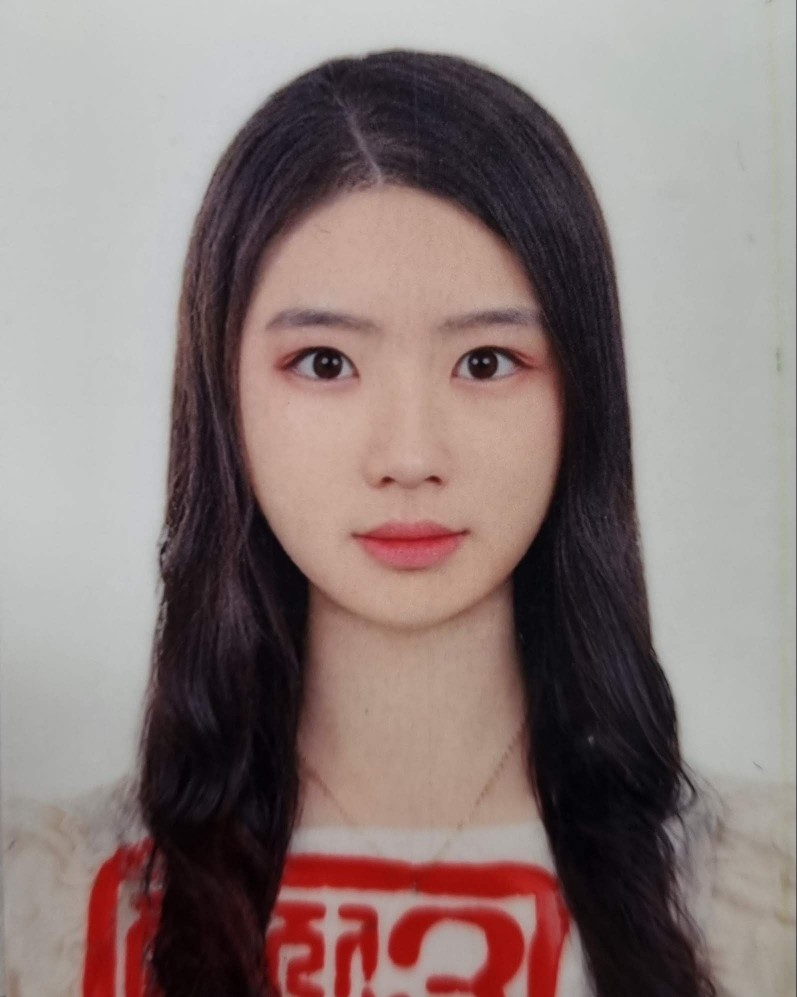

In [42]:
Image.open(img_path).convert("RGB")

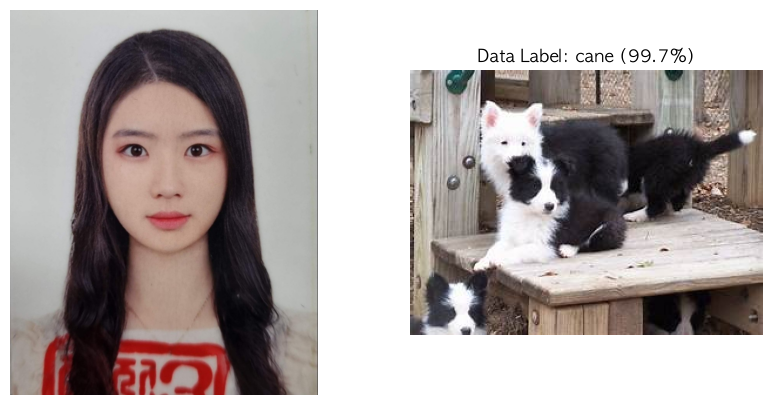

In [48]:
image = Image.open(img_path).convert("RGB")
input_tensor = test_transform(image)
input_tensor_dev = input_tensor.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]
    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100

dataset_sample_img = None
# for sample_img, sample_label in base_dataset:
for sample_img, sample_label in train_subset:
    if sample_label == pred_idx:
        dataset_sample_img = sample_img
        break

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image)
axes[0].axis("off")

axes[1].imshow(dataset_sample_img)
axes[1].set_title(f"Data Label: {pred_class} ({confidence:.1f}%)")
axes[1].axis("off")
plt.show()